# NB extension · The Lévy walk, and all random walks side by side

An optional extension of NB2. NB2 treats Brownian motion, run-and-tumble and the biased random walk one by one. This notebook adds one more strategy, the **Lévy walk**, and then compares **five model walkers** side by side, with matched parameters:

| | Model | Rule | Equation of motion |
|---|---|---|---|
| 1 | **Random walk** | every step is independent and random | $\mathbf r_{n+1}=\mathbf r_n+\sqrt{2D\,\Delta t}\;\boldsymbol\xi_n$ |
| 2 | **Biased random walk** | random steps plus a constant drift | $\mathbf r_{n+1}=\mathbf r_n+\mathbf v_d\,\Delta t+\sqrt{2D\,\Delta t}\;\boldsymbol\xi_n$ |
| 3 | **Persistent walk: run-and-tumble** | swim straight at speed $v$; at rate $\lambda$ pick a new direction | $\dot{\mathbf r}=v\,\hat{\mathbf e}(\theta)$, $\theta$ jumps at rate $\lambda$ |
| 4 | **Persistent walk: smooth turner** | swim at speed $v$; the direction diffuses | $\dot{\mathbf r}=v\,\hat{\mathbf e}(\theta)$, $\dot\theta=\sqrt{2D_r}\,\xi$ |
| 5 | **Lévy walk** | like (3), but run durations are heavy-tailed: a few runs are *very* long | see section 2 |

Here $\hat{\mathbf e}(\theta)=(\cos\theta,\sin\theta)$ is the swimming direction and $\boldsymbol\xi_n$, $\xi$ are Gaussian random numbers. Models 3 and 4 both forget their direction after a **persistence time** $\tau_p$ (here 1 s), and spread at long times with $D_\text{eff}=v^2\tau_p/2$. We set the random walk's $D$ equal to this $D_\text{eff}$, so models 1, 3 and 4 spread equally fast at long times.

**About the curves.** Every MSD averages 1000 simulated tracks of 400 s and stops at a lag of 40 s, so the curves show the models, not the limits of measurement. The notebook runs in about two minutes. Cells marked **🔧 Try it** are meant to be edited and re-run.

## 0 · Setup
Only `numpy`, `matplotlib` and `seaborn` are needed (all in the course environment).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("white")
sns.set_context("talk")
plt.rcParams.update({"legend.frameon": False, "figure.dpi": 80})

rng = np.random.default_rng(2026)   # fixed seed -> everyone gets the same figures

# ---- imaging settings (similar to our microscope movies)
DT = 0.02          # s per frame (50 frames per second)
T = 400.0          # s, length of each simulated track (much longer than real tracks!)
N_FRAMES = int(round(T / DT)) + 1
BATCH = 100        # tracks simulated at once (and kept for plotting)
N_BATCHES = 10     # MSDs average over N_BATCHES * BATCH = 1000 tracks

# ---- model parameters, matched so that the models are comparable
V = 20.0                    # µm/s   swimming speed (models 3, 4)
TAU_P = 1.0                 # s      persistence time (model 3)
LAM = 1 / TAU_P             # 1/s    tumble rate (run-and-tumble, uniform new heading)
DR = 1 / TAU_P              # 1/s    rotational diffusion (smooth turner)
D = V**2 * TAU_P / 2        # µm²/s  = 200: random walk D matched to the long-time D_eff of model 3
VD = 10.0                   # µm/s   drift speed (model 2); exaggerated so the crossover is visible
MU = 1.5                    # Lévy exponent, run-duration density ~ t^-(1+MU)
T0 = (MU - 1) / MU * TAU_P  # s      minimum Lévy run; chosen so the MEAN run is also 1 s

# one fixed color + line pattern per model, used in every figure
COLORS = {"rw": "#2a78d6", "biased": "#eb6834", "rtp": "#1baf7a", "levy": "#eda100", "abp": "#e87ba4"}
STYLE = {"rw":     dict(color=COLORS["rw"], ls="-"),
         "biased": dict(color=COLORS["biased"], ls=(0, (6, 2))),
         "rtp":    dict(color=COLORS["rtp"], ls="-"),
         "levy":   dict(color=COLORS["levy"], ls=(0, (6, 2, 1.5, 2))),
         "abp":    dict(color=COLORS["abp"], ls=(0, (1.5, 1.5)))}
GRAY = dict(color="0.45", ls=(0, (3, 2)))
THEORY_KW = dict(color="0.1", lw=2)
print(f"D = {D:.0f} µm²/s, Lévy t0 = {T0:.3f} s")

D = 200 µm²/s, Lévy t0 = 0.333 s


### Simulation functions
Each function returns positions with shape `(n_tracks, n_frames, 2)` in µm, one row per frame, every track starting at the origin. You don't need to read every line, but notice that **each function is just its equation of motion** written as a loop or a cumulative sum.

In [2]:
def heading(theta):
    """Unit vector e(theta) = (cos theta, sin theta)."""
    return np.stack([np.cos(theta), np.sin(theta)], axis=-1)


def simulate_rw(n_tracks, T, dt, D, rng):
    """Random walk:  r_{n+1} = r_n + sqrt(2 D dt) * xi_n."""
    nf = int(round(T / dt)) + 1
    steps = np.sqrt(2 * D * dt) * rng.standard_normal((n_tracks, nf - 1, 2))
    r = np.zeros((n_tracks, nf, 2))
    r[:, 1:] = np.cumsum(steps, axis=1)
    return r


def simulate_biased_rw(n_tracks, T, dt, D, vd, rng):
    """Biased random walk:  r_{n+1} = r_n + vd*dt*x_hat + sqrt(2 D dt) * xi_n."""
    nf = int(round(T / dt)) + 1
    steps = np.sqrt(2 * D * dt) * rng.standard_normal((n_tracks, nf - 1, 2))
    steps[..., 0] += vd * dt
    r = np.zeros((n_tracks, nf, 2))
    r[:, 1:] = np.cumsum(steps, axis=1)
    return r


def simulate_rtp(n_tracks, T, dt, v, lam, rng, eps=0.0, turn_angle=None):
    """Run-and-tumble: swim at speed v along theta. In each frame, tumble with
    probability lam * (1 - eps*cos(theta)) * dt  (eps > 0: fewer tumbles when heading toward +x).
    turn_angle=None -> new heading uniform in [0, 2pi); otherwise theta -> theta + turn_angle(rng, k).
    Returns (positions, tumbled); tumbled[i, n] is True if track i tumbled at frame n."""
    nf = int(round(T / dt)) + 1
    theta = rng.uniform(0, 2 * np.pi, n_tracks)
    r = np.zeros((n_tracks, nf, 2))
    tumbled = np.zeros((n_tracks, nf), dtype=bool)
    for n in range(1, nf):
        r[:, n] = r[:, n - 1] + v * dt * heading(theta)
        tum = rng.random(n_tracks) < lam * (1 - eps * np.cos(theta)) * dt
        k = tum.sum()
        if k:
            theta[tum] = rng.uniform(0, 2 * np.pi, k) if turn_angle is None else theta[tum] + turn_angle(rng, k)
        tumbled[:, n] = tum
    return r, tumbled


def simulate_abp(n_tracks, T, dt, v, Dr, rng, Dt=0.0):
    """Smooth turner (active Brownian particle):
    theta_{n+1} = theta_n + sqrt(2 Dr dt) * xi,   r_{n+1} = r_n + v dt e(theta_n)  [+ sqrt(2 Dt dt) * xi']."""
    nf = int(round(T / dt)) + 1
    theta0 = rng.uniform(0, 2 * np.pi, (n_tracks, 1))
    dtheta = np.sqrt(2 * Dr * dt) * rng.standard_normal((n_tracks, nf - 2))
    theta = theta0 + np.concatenate([np.zeros((n_tracks, 1)), np.cumsum(dtheta, axis=1)], axis=1)
    steps = v * dt * heading(theta)
    if Dt > 0:
        steps += np.sqrt(2 * Dt * dt) * rng.standard_normal(steps.shape)
    r = np.zeros((n_tracks, nf, 2))
    r[:, 1:] = np.cumsum(steps, axis=1)
    return r


def pareto_durations(n, mu, t0, rng):
    """Heavy-tailed run durations, psi(t) = mu t0^mu / t^(1+mu) for t >= t0."""
    return t0 * (1.0 - rng.random(n)) ** (-1.0 / mu)


def simulate_levy(n_tracks, T, dt, v, mu, t0, rng, t_burn=None):
    """Lévy walk: constant speed v, uniform new heading for every run, Pareto run durations.
    The walk starts t_burn before the first frame, so frame 0 falls in the middle of a run."""
    nf = int(round(T / dt)) + 1
    t = np.arange(nf) * dt
    t_burn = T if t_burn is None else t_burn
    out = np.empty((n_tracks, nf, 2))
    for i in range(n_tracks):
        durs, total = [], 0.0
        while total < T + t_burn:
            d = pareto_durations(1000, mu, t0, rng)
            durs.append(d)
            total += d.sum()
        durs = np.concatenate(durs)
        ends = np.cumsum(durs) - t_burn                 # end time of each run
        last = np.searchsorted(ends, T) + 1             # keep runs up to the one that covers T
        durs, ends = durs[:last], ends[:last]
        starts = ends - durs
        theta = rng.uniform(0, 2 * np.pi, last)
        r_start = np.vstack([[0.0, 0.0], np.cumsum(v * durs[:, None] * heading(theta), axis=0)[:-1]])
        k = np.searchsorted(ends, t, side="right")      # index of the run containing each frame
        pos = r_start[k] + v * (t - starts[k])[:, None] * heading(theta[k])
        out[i] = pos - pos[0]
    return out

### Analysis and plotting functions
`msd` is the function you will reuse on the real datasets.

In [3]:
def log_lags(n_frames, max_frac=0.1, n=30):
    """Log-spaced integer lags (in frames), from 1 up to max_frac * n_frames."""
    return np.unique(np.logspace(0, np.log10(max_frac * n_frames), n).astype(int))


def msd(tracks, lags):
    """Time- and ensemble-averaged MSD:  < |r(t + lag) - r(t)|^2 >  over start times t and all tracks.
    For long lags, start times are spaced lag/10 frames apart: heavily overlapping windows add
    almost no new information, and skipping them keeps this fast."""
    out = []
    for k in lags:
        s = max(1, k // 10)
        d = tracks[:, k::s] - tracks[:, :-k:s]
        out.append(np.mean(np.sum(d**2, axis=-1)))
    return np.array(out)


def local_slope(tau, m):
    """alpha(tau) = d log MSD / d log tau."""
    return np.gradient(np.log(m), np.log(tau))


def vacf(tracks, dt, max_lag):
    """Velocity autocorrelation C(s) = < v(t) . v(t+s) > from frame-to-frame velocities, s = 0..max_lag frames."""
    vel = np.diff(tracks, axis=1) / dt
    n = vel.shape[1]
    return np.array([np.mean(np.sum(vel[:, : n - k] * vel[:, k:], axis=-1)) for k in range(max_lag + 1)])


# ---- theory curves
def msd_theory_rw(tau, D):
    return 4 * D * tau

def msd_theory_biased(tau, D, vd):
    return 4 * D * tau + vd**2 * tau**2

def msd_theory_persistent(tau, v, tau_p, Dt=0.0):
    return 2 * v**2 * tau_p**2 * (tau / tau_p - 1 + np.exp(-tau / tau_p)) + 4 * Dt * tau


# ---- lags used in sections 2-7: 1 frame ... T/10 = 40 s
LAGS = log_lags(N_FRAMES)
TAU = LAGS * DT
TAU_FINE = np.logspace(np.log10(TAU[0]), np.log10(TAU[-1]), 300)


def msd_many(simulate, n_batches=N_BATCHES, include=None, lags=None):
    """MSD averaged over n_batches batches of tracks; simulate() returns one new batch.
    If `include` (a batch you already simulated) is given, it counts as the first batch.
    Only one batch is in memory at a time."""
    lags = LAGS if lags is None else lags
    total = msd(include, lags) if include is not None else 0.0
    for _ in range(n_batches - (include is not None)):
        total = total + msd(simulate(), lags)
    return total / n_batches


# ---- figures
def plot_tracks(tracks, color, title, n_show=5, windows=(2, 60), lims=(80, 800)):
    """Example tracks over a short and a long window, on fixed axes shared by all models."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, w, L in zip(axes, windows, lims):
        k = int(round(w / DT)) + 1
        for tr in tracks[:n_show]:
            ax.plot(tr[:k, 0], tr[:k, 1], color=color, lw=1.2, alpha=0.85)
            ax.plot(tr[k - 1, 0], tr[k - 1, 1], "o", ms=6, color=color)
        ax.plot(0, 0, "+", color="k", ms=14, mew=2)
        ax.set(xlim=(-L, L), ylim=(-L, L), aspect="equal", xlabel="x (µm)", ylabel="y (µm)",
               title=f"first {w} s  (+ start, ● end)")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def msd_figure(curves, theory=(), vlines=(), alpha_lines=(), slopes=(), title=""):
    """Left: MSD on log-log axes. Right: local exponent alpha(tau).
    curves:      list of (tau, msd, style, label), style = dict(color=..., ls=...).
                 Earlier curves are drawn thicker and underneath, so overlapping curves stay visible.
    theory:      list of (tau, msd, label), drawn as thin black dashed / dotted lines on top.
    vlines:      list of (tau, label), e.g. a crossover time.
    alpha_lines: extra horizontal reference lines on the alpha panel, list of (alpha, label).
    slopes:      reference segments on the MSD panel, list of (alpha, tau_start, tau_end[, offset]),
                 drawn next to the first curve (offset 0.3 = a bit below it, default; offset > 1 = above it)."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.2))
    n = len(curves)
    for i, (tau, m, style, label) in enumerate(curves):
        kw = dict(lw=max(2.0, 5.5 - 1.2 * i), alpha=0.9, zorder=2 + i, **style)
        ax1.loglog(tau, m, label=label, **kw)
        ax2.semilogx(tau, local_slope(tau, m), **kw)
    for i, (tau, m, label) in enumerate(theory):
        ls = ["--", ":"][i % 2]
        ax1.loglog(tau, m, ls=ls, label=label, zorder=10, **THEORY_KW)
        ax2.semilogx(tau, local_slope(tau, m), ls=ls, zorder=10, **THEORY_KW)
    if slopes:
        tau0, m0 = curves[0][0], curves[0][1]
        for seg in slopes:
            a, t1, t2 = seg[:3]
            offset = seg[3] if len(seg) > 3 else 0.3      # < 1: below the curve, > 1: above it
            y1 = offset * np.exp(np.interp(np.log(t1), np.log(tau0), np.log(m0)))
            y2 = y1 * (t2 / t1) ** a
            ax1.plot([t1, t2], [y1, y2], color="0.25", lw=2.5, solid_capstyle="butt", zorder=11)
            below = offset < 1
            ax1.text(np.sqrt(t1 * t2), np.sqrt(y1 * y2) * (0.4 if below else 2.5), f"slope {a:g}",
                     ha="right" if not below else "left", va="top" if below else "bottom",
                     fontsize="x-small", color="0.25")
    for a, lab in [(1, "diffusive (α = 1)"), (2, "ballistic (α = 2)")] + list(alpha_lines):
        ax2.axhline(a, color="0.75", lw=1.2, zorder=1)
        ax2.text(0.01, a + 0.04, lab, transform=ax2.get_yaxis_transform(), fontsize="x-small", color="0.35")
    for x, lab in vlines:
        for ax in (ax1, ax2):
            ax.axvline(x, color="0.55", lw=1.2, ls=":", zorder=1)
        ax2.text(x * 1.1, 0.1, lab, ha="left", fontsize="x-small", color="0.3")
    ax1.set(xlabel="lag τ (s)", ylabel="MSD (µm²)", title="MSD(τ)")
    ax2.set(xlabel="lag τ (s)", ylabel="α(τ) = d log MSD / d log τ", ylim=(-0.1, 2.3),
            title="local exponent α(τ)")
    ax1.legend(fontsize="x-small", loc="upper left")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## 1 · Simulate models 1–4

The MSDs of models 1–4 are known exactly (NB2 derives them); each simulation is checked against its formula:

| Model | MSD |
|---|---|
| Random walk | $4D\tau$ |
| Biased random walk | $4D\tau+v_d^2\tau^2$ |
| Run-and-tumble, smooth turner | $2v^2\tau_p^2\left(\tau/\tau_p-1+e^{-\tau/\tau_p}\right)$ |

In [4]:
# 1. Random walk
sim_rw = lambda: simulate_rw(BATCH, T, DT, D, rng)
tracks_rw = sim_rw()
msd_rw = msd_many(sim_rw, include=tracks_rw)

# 2. Biased random walk (drift toward +x)
sim_b = lambda: simulate_biased_rw(BATCH, T, DT, D, VD, rng)
tracks_b = sim_b()
msd_b = msd_many(sim_b, include=tracks_b)
tau_c = 4 * D / VD**2                      # crossover time: drift and diffusion contribute equally

# 3. Run-and-tumble (uniform new direction at each tumble)
tracks_rtp, _ = simulate_rtp(BATCH, T, DT, V, LAM, rng)
msd_rtp = msd_many(lambda: simulate_rtp(BATCH, T, DT, V, LAM, rng)[0], include=tracks_rtp)

# 4. Smooth turner
sim_abp = lambda: simulate_abp(BATCH, T, DT, V, DR, rng)
tracks_abp = sim_abp()
msd_abp = msd_many(sim_abp, include=tracks_abp)

## 2 · Lévy walk

**Equation of motion.** The same as run-and-tumble (constant speed, uniform new heading for every run), but run durations come from a **heavy-tailed (Pareto) distribution**:
$$\psi(t)=\frac{\mu\,t_0^{\mu}}{t^{1+\mu}}\quad(t\ge t_0),\qquad\text{sampled as } t_k=t_0\,U^{-1/\mu},\ U\sim\text{Uniform}(0,1),\qquad\langle t\rangle=\frac{\mu\,t_0}{\mu-1}.$$
During run $k$, which starts at time $T_k$: $\ \mathbf r(t)=\mathbf r(T_k)+v\,(t-T_k)\,\hat{\mathbf e}(\theta_k)$.

We use $\mu=1.5$ and $t_0=1/3$ s, so the **mean run is 1 s, the same as our run-and-tumble swimmer**, at the same speed. Only the *tail* of the run-duration distribution differs.

**MSD.** Seen from far away, each run of a run-and-tumble swimmer is one big step of length $\ell=vt$, and a random walk of big steps spreads with $D_\text{eff}=\langle\ell^2\rangle/(4\langle t\rangle)$. For a Lévy walk with $\mu<2$ this breaks: $\langle\ell^2\rangle=\infty$, so there is no finite $D_\text{eff}$ and the walk never becomes diffusive:

| $\mu$ | long-lag MSD |
|---|---|
| $0<\mu<1$ | $\sim\tau^2$ (ballistic forever) |
| $1<\mu<2$ | $\sim\tau^{\,3-\mu}$ (**superdiffusive**) |
| $\mu>2$ | $\sim\tau$ (diffusive) |

At short lags ($\tau\ll t_0$) it is ballistic, $v^2\tau^2$. (A *Lévy flight* instead makes instantaneous jumps with no speed limit, and its MSD is infinite.)

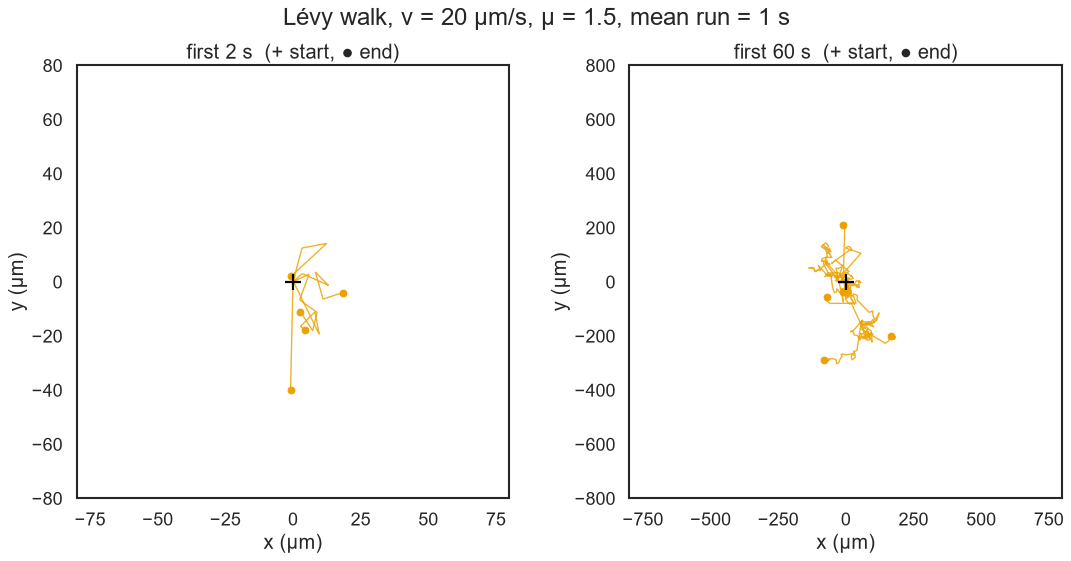

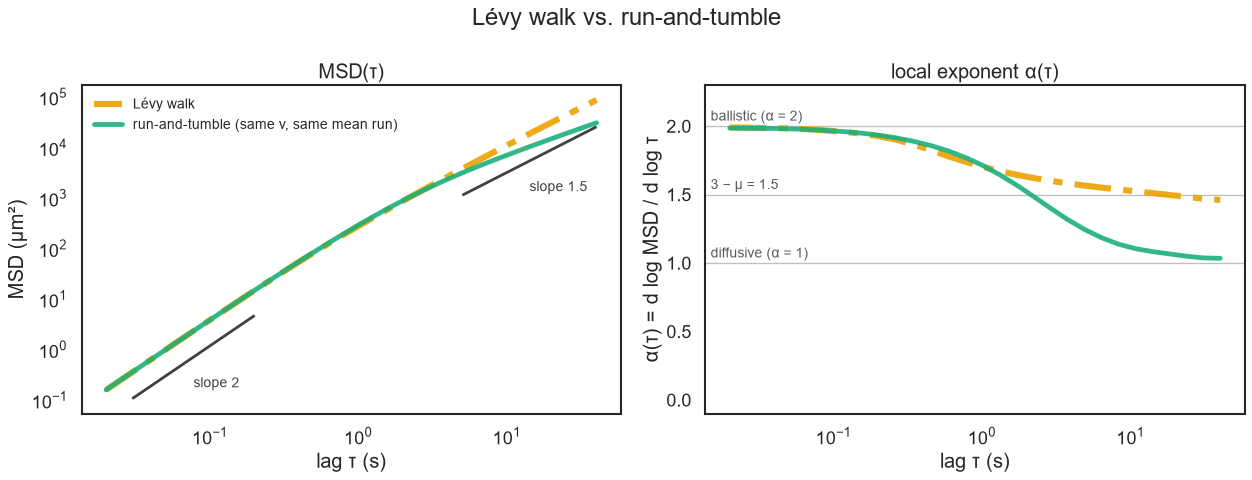

mean α for lags 10–40 s: 1.49  (theory 3 − μ = 1.5)


In [5]:
sim_levy = lambda: simulate_levy(BATCH, T, DT, V, MU, T0, rng)
tracks_levy = sim_levy()
plot_tracks(tracks_levy, COLORS["levy"], f"Lévy walk, v = {V:.0f} µm/s, μ = {MU}, mean run = 1 s")

msd_levy = msd_many(sim_levy, include=tracks_levy)
msd_figure([(TAU, msd_levy, STYLE["levy"], "Lévy walk"),
            (TAU, msd_rtp, STYLE["rtp"], "run-and-tumble (same v, same mean run)")],
           alpha_lines=[(3 - MU, f"3 − μ = {3 - MU}")],
           slopes=[(2, 0.03, 0.2), (3 - MU, 5, 40)],
           title="Lévy walk vs. run-and-tumble")
a_long = local_slope(TAU, msd_levy)[TAU > 10].mean()
print(f"mean α for lags 10–40 s: {a_long:.2f}  (theory 3 − μ = {3 - MU})")

**Why it never becomes diffusive.** Left: the fraction of runs longer than $t$. Exponential runs essentially never last 10 s; Pareto runs sometimes last 100 s. Right: the running average of $\ell^2$ as we include more and more runs. For exponential runs it settles at $2v^2\tau_p^2$. For Lévy runs it keeps jumping up whenever a rare, very long run arrives: the average does not converge, because $\langle\ell^2\rangle=\infty$.

mean run duration: exponential 1.00 s, Pareto 0.98 s


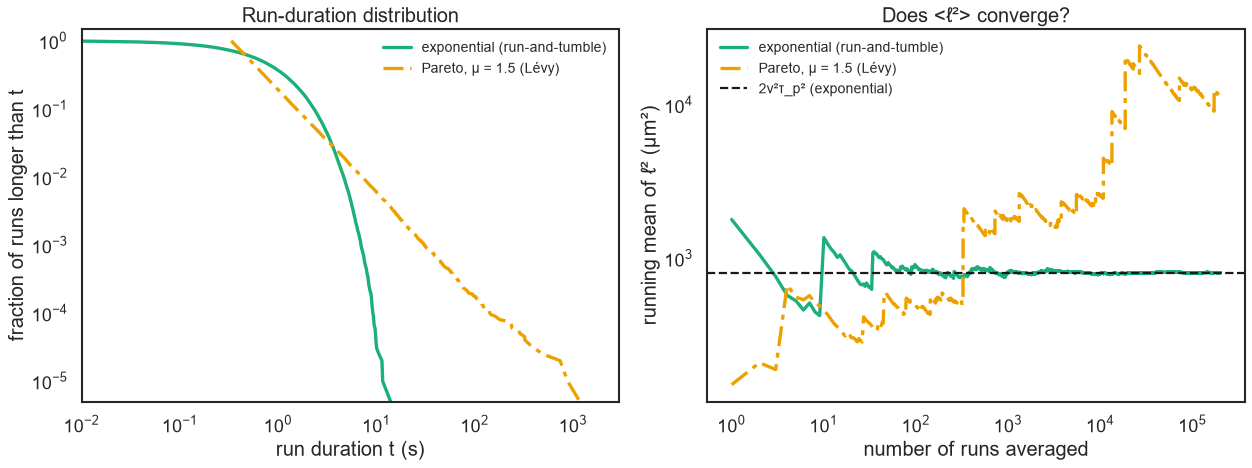

In [6]:
n_runs = 200_000
t_exp = rng.exponential(TAU_P, n_runs)
t_par = pareto_durations(n_runs, MU, T0, rng)
print(f"mean run duration: exponential {t_exp.mean():.2f} s, Pareto {t_par.mean():.2f} s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.2))
for t_, key, lab in [(t_exp, "rtp", "exponential (run-and-tumble)"), (t_par, "levy", f"Pareto, μ = {MU} (Lévy)")]:
    ts = np.sort(t_)
    ax1.loglog(ts, 1 - np.arange(len(ts)) / len(ts), lw=3, label=lab, **STYLE[key])
    n = np.arange(1, n_runs + 1)
    ax2.loglog(n, np.cumsum((V * t_) ** 2) / n, lw=3, label=lab, **STYLE[key])
ax1.set(xlabel="run duration t (s)", ylabel="fraction of runs longer than t", ylim=(1 / n_runs, 1.5), xlim=(1e-2, None),
        title="Run-duration distribution")
ax2.axhline(2 * V**2 * TAU_P**2, ls="--", label="2v²τ_p² (exponential)", **THEORY_KW)
ax2.set(xlabel="number of runs averaged", ylabel="running mean of ℓ² (µm²)", title="Does <ℓ²> converge?")
ax1.legend(fontsize="x-small"); ax2.legend(fontsize="x-small")
fig.tight_layout()
plt.show()

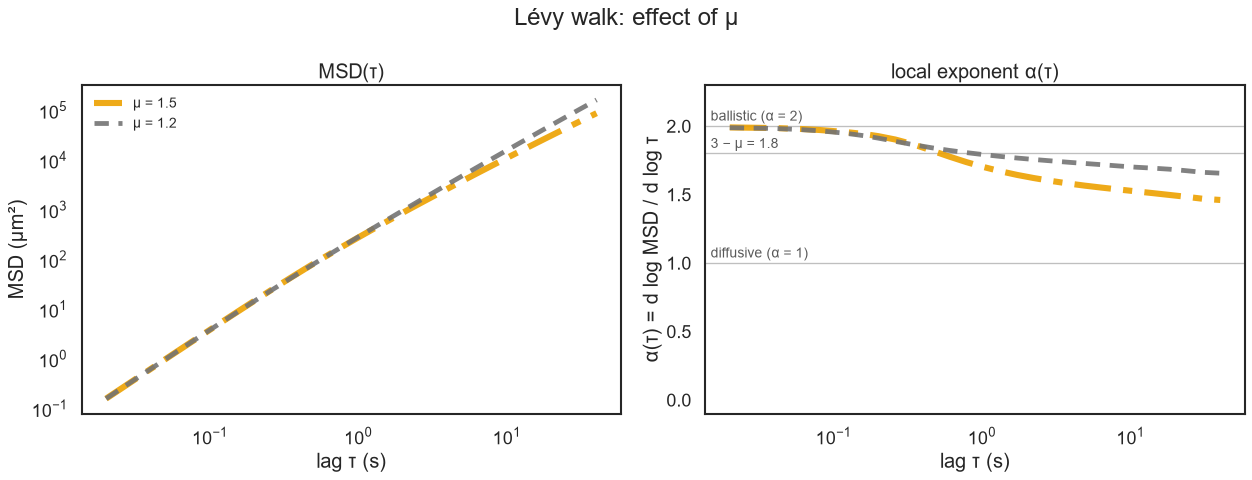

In [7]:
# 🔧 Try it: change MU_try (keep it above 1 so the mean run exists). Predict the long-lag α before running.
MU_try = 1.2
T0_try = (MU_try - 1) / MU_try      # keeps the mean run at 1 s
msd_try = msd_many(lambda: simulate_levy(BATCH, T, DT, V, MU_try, T0_try, rng), n_batches=3)
msd_figure([(TAU, msd_levy, STYLE["levy"], f"μ = {MU}"), (TAU, msd_try, GRAY, f"μ = {MU_try}")],
           alpha_lines=[(3 - MU_try, f"3 − μ = {3 - MU_try:.1f}")],
           title="Lévy walk: effect of μ")

## 3 · All five walks side by side

Same axes for every model. In the short window, look at the **shape** of the tracks; in the long window, at **how far** they get.

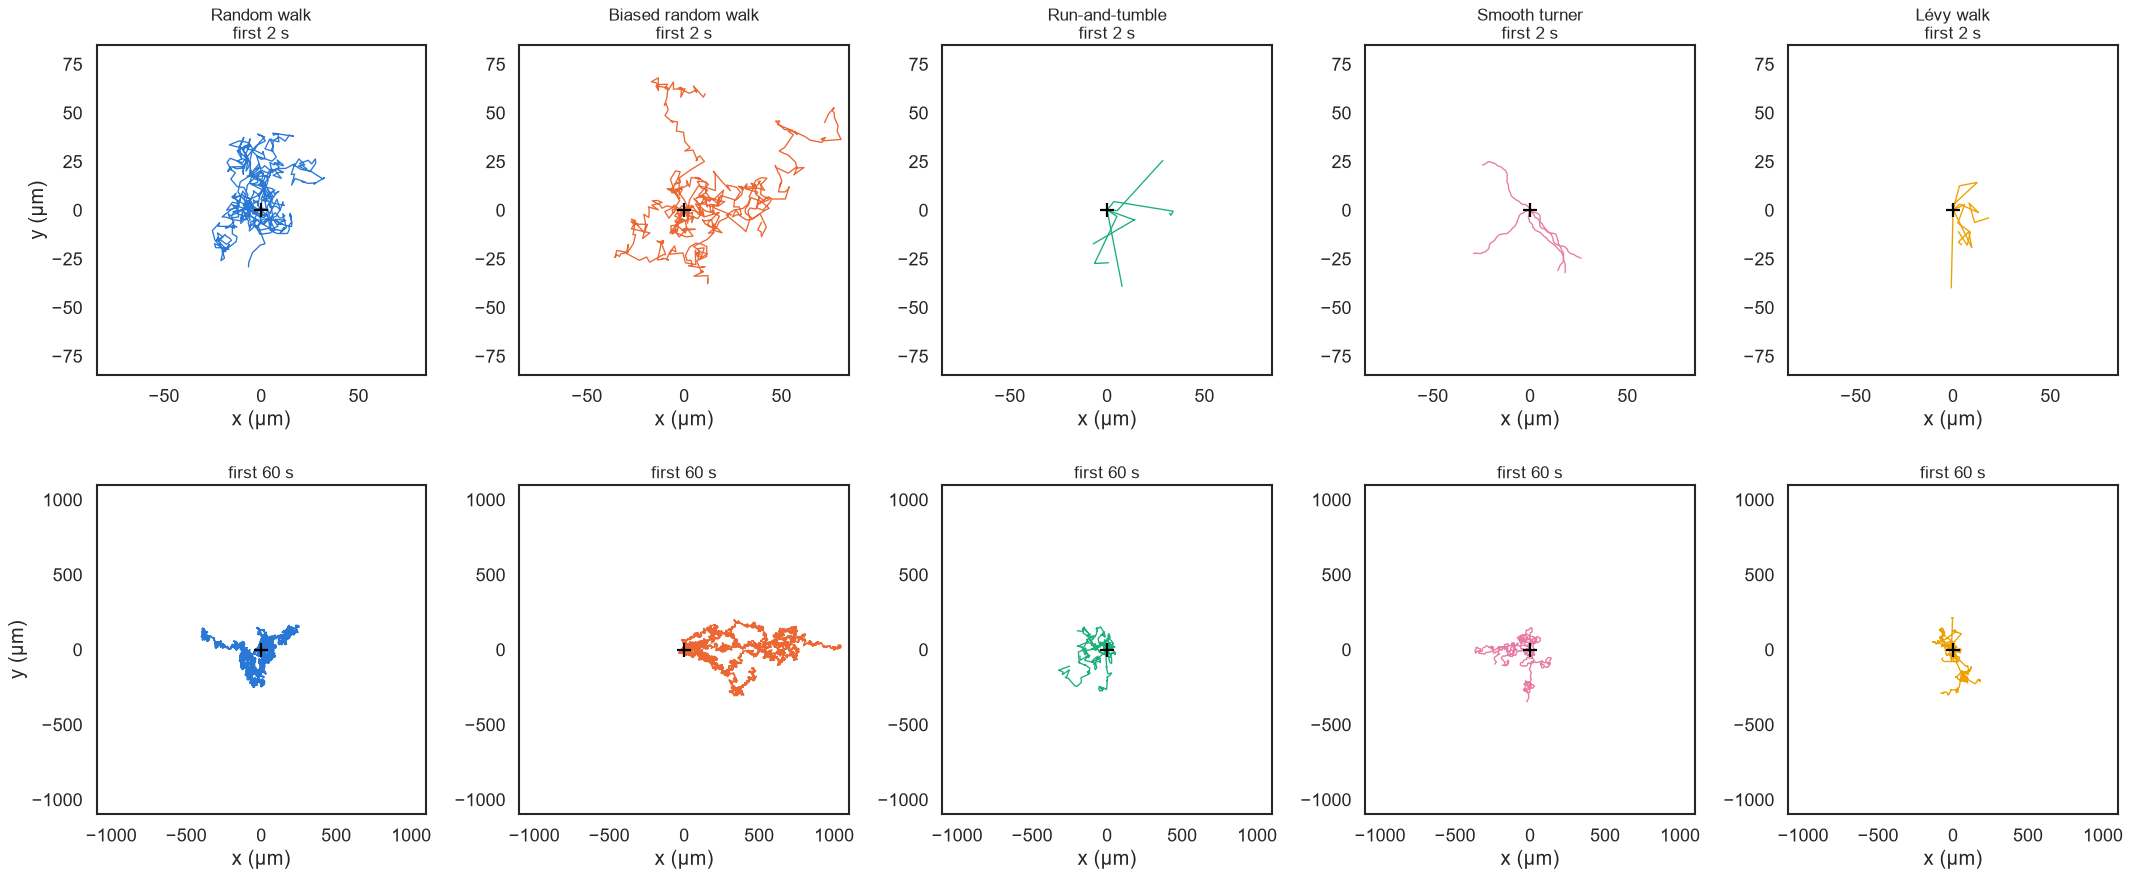

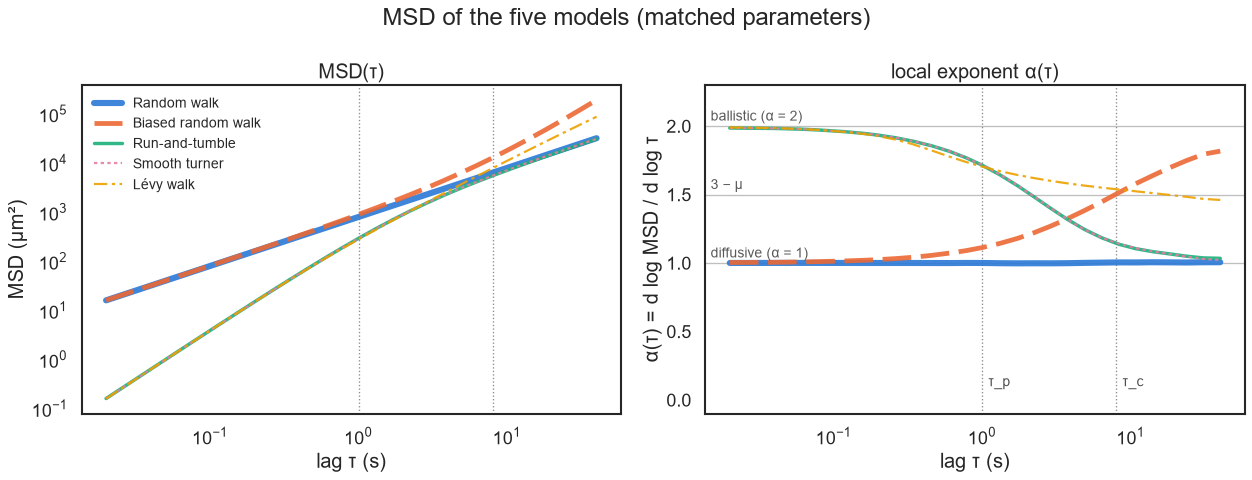

In [8]:
models = [("Random walk", tracks_rw, msd_rw, "rw"),
          ("Biased random walk", tracks_b, msd_b, "biased"),
          ("Run-and-tumble", tracks_rtp, msd_rtp, "rtp"),
          ("Smooth turner", tracks_abp, msd_abp, "abp"),
          ("Lévy walk", tracks_levy, msd_levy, "levy")]

fig, axes = plt.subplots(2, 5, figsize=(27, 11.5))
for row, w in enumerate((2, 60)):
    k = int(round(w / DT)) + 1
    L = 1.05 * max(np.abs(tr[:5, :k]).max() for _, tr, _, _ in models)
    for col, (name, tr, _, key) in enumerate(models):
        ax = axes[row, col]
        for one in tr[:5]:
            ax.plot(one[:k, 0], one[:k, 1], color=COLORS[key], lw=1.2)
        ax.plot(0, 0, "+", color="k", ms=12, mew=2)
        ax.set(xlim=(-L, L), ylim=(-L, L), aspect="equal", xlabel="x (µm)")
        ax.set_title(f"{name}\nfirst {w} s" if row == 0 else f"first {w} s", fontsize="small")
        if col == 0:
            ax.set_ylabel("y (µm)")
fig.tight_layout()
plt.show()

msd_figure([(TAU, m, STYLE[key], name) for name, _, m, key in models],
           alpha_lines=[(3 - MU, "3 − μ")], vlines=[(TAU_P, "τ_p"), (tau_c, "τ_c")],
           title="MSD of the five models (matched parameters)")

| Model | short lags | long lags | $\alpha(\tau)$ |
|---|---|---|---|
| Random walk | $4D\tau$ | $4D\tau$ | flat at 1 |
| Biased random walk | $4D\tau$ | $v_d^2\tau^2$ | 1 → 2 around the crossover time $\tau_c=4D/v_d^2$ |
| Run-and-tumble | $v^2\tau^2$ | $4D_\text{eff}\tau$, $D_\text{eff}=v^2\tau_p/2$ | 2 → 1 around the persistence time $\tau_p$ |
| Smooth turner | $v^2\tau^2$ | $4D_\text{eff}\tau$, $D_\text{eff}=v^2\tau_p/2$ | the same as run-and-tumble |
| Lévy walk ($1<\mu<2$) | $v^2\tau^2$ | $\sim\tau^{3-\mu}$ | 2 → $3-\mu$ |

What the comparison shows:
* The random walk and the two persistent walks end up with the **same** long-time MSD. They differ only at lags shorter than about $\tau_p$, so you need a frame rate fast enough to see that range.
* Run-and-tumble and the smooth turner have **identical** MSDs, although one turns suddenly and the other gradually. The MSD cannot tell them apart; the turning angles between frames can (NB1, the $(v,\omega)$ state space).
* The Lévy walk and the biased walk both stay above $\alpha=1$ at long lags, for different reasons: rare very long runs, or a constant drift. The mean displacement separates them: only the biased walk has one.

## 4 · Going further (optional)

<details>
<summary><b>Why α = 3 − μ for the Lévy walk</b></summary>

For $1<\mu<2$, the MSD at lag $\tau$ is dominated by the longest runs that fit inside the window. Such a run contributes $\sim(v\tau)^2$, and a fraction $\sim\tau^{1-\mu}$ of the time is spent in runs longer than $\tau$. Together: $\mathrm{MSD}\sim v^2\tau^2\cdot\tau^{1-\mu}=v^2\tau^{3-\mu}$. See Zaburdaev, Denisov & Klafter, *Rev. Mod. Phys.* 87, 483 (2015).
</details>

**Questions**
1. A dataset's MSD has $\alpha\approx2$ at every lag you can measure. Which of the five models could have produced it? What other measurement would separate them?
2. Two datasets have the same $D_\text{eff}$. One has $\alpha(\tau)$ crossing 1.5 at 0.3 s, the other at 3 s. What does that tell you about their persistence times?
3. Real tracks last only ~10 s. Which differences between the five models could you still see?